# Notebook 07 - Temporal Transformer Model (Final Model)

This notebook trains the **Temporal Transformer** - the final and most powerful model in this pipeline.

**Architecture:** Pre-trained Spatial Encoder → Sequence of Latent Tokens → Transformer Encoder → Flood Segmentation Mask

**Stages:**
1. Temporal sequence preparation
2. TemporalTransformerPredictor architecture
3. Training with IoU-based early stopping
4. Training curves
5. Prediction on test sequences
6. Spatio-temporal change detection
7. Flood area metrics

## Step 1: Imports & Setup

In [1]:
import os, sys
# Set project root path cleanly
ROOT_DIR = os.path.abspath('..') if os.path.exists('../config.json') else os.path.abspath('.')
if ROOT_DIR not in sys.path:
    sys.path.insert(0, ROOT_DIR)

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from torch.utils.data import DataLoader
from dataset import TrueTimeSeriesSARDataset, get_train_val_test_splits
from models import TemporalTransformerPredictor
from utils import set_seed, load_config, calculate_metrics
from torch.optim.lr_scheduler import ReduceLROnPlateau

config = load_config(os.path.join(ROOT_DIR, 'config.json'))
set_seed(config['training']['seed'])
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

plt.rcParams['figure.facecolor'] = '#0d1117'
plt.rcParams['axes.facecolor'] = '#161b22'
plt.rcParams['text.color'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'white'
plt.rcParams['ytick.color'] = 'white'

print(f'Using device: {device}')


Using device: cpu


## Step 2: Build Temporal Sequences

In [2]:
S1_DIR = os.path.join(ROOT_DIR, config['data']['s1_dir'])
LABEL_DIR = os.path.join(ROOT_DIR, config['data']['label_dir'])
SEQ_LENGTH = config['data']['seq_length']
TARGET_SIZE = tuple(config['data']['target_size'])

s1_files = sorted([f for f in os.listdir(S1_DIR) if f.endswith('.tif')])
label_files = sorted([f for f in os.listdir(LABEL_DIR) if f.endswith('.tif')])

sequences = []
for i in range(len(s1_files) - SEQ_LENGTH + 1):
    s1_seq = [os.path.join(S1_DIR, s1_files[i+j]) for j in range(SEQ_LENGTH)]
    label_path = os.path.join(LABEL_DIR, label_files[i+SEQ_LENGTH-1])
    sequences.append((s1_seq, label_path))

print(f'Sequence length T = {SEQ_LENGTH}')
print(f'Total sequences: {len(sequences)}')

train_idx, val_idx, test_idx = get_train_val_test_splits(len(sequences), config['data']['split_ratio'])
train_seqs = [sequences[i] for i in train_idx]
val_seqs   = [sequences[i] for i in val_idx]
test_seqs  = [sequences[i] for i in test_idx]

train_dataset = TrueTimeSeriesSARDataset(train_seqs, seq_length=SEQ_LENGTH, target_size=TARGET_SIZE)
val_dataset   = TrueTimeSeriesSARDataset(val_seqs,   seq_length=SEQ_LENGTH, target_size=TARGET_SIZE)
test_dataset  = TrueTimeSeriesSARDataset(test_seqs,  seq_length=SEQ_LENGTH, target_size=TARGET_SIZE)

train_loader = DataLoader(train_dataset, batch_size=config['training']['batch_size'], shuffle=True,  num_workers=config['data']['num_workers'])
val_loader   = DataLoader(val_dataset,   batch_size=config['training']['batch_size'], shuffle=False, num_workers=config['data']['num_workers'])
test_loader  = DataLoader(test_dataset,  batch_size=1,                                shuffle=False)

print(f'Train/Val/Test sequences: {len(train_seqs)}/{len(val_seqs)}/{len(test_seqs)}')


Sequence length T = 3
Total sequences: 38
Train/Val/Test sequences: 26/5/7


## Step 3: Transformer Model Architecture

In [3]:
model = TemporalTransformerPredictor(
    seq_length=config['data']['seq_length'],
    embed_dim=config['model']['transformer_embed_dim'],
    num_heads=config['model']['transformer_heads'],
    hidden_dim=config['model']['transformer_hidden_dim'],
    num_layers=config['model']['transformer_layers'],
    dropout=config['model']['dropout_rate']
).to(device)

encoder_path = os.path.join(ROOT_DIR, 'models/encoder.pth')
if os.path.exists(encoder_path):
    model.spatial_encoder.encoder.load_state_dict(torch.load(encoder_path, weights_only=True))
    print('Loaded pretrained spatial encoder weights!')
else:
    print('No pretrained encoder found - training from scratch')

total_params = sum(p.numel() for p in model.parameters())
trainable   = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'\nTotal parameters: {total_params:,}')
print(f'Trainable:        {trainable:,}')


Loaded pretrained spatial encoder weights!

Total parameters: 20,736,514
Trainable:        20,736,514


## Step 4: Training the Temporal Transformer

In [4]:
criterion = nn.CrossEntropyLoss(ignore_index=-1)
optimizer = torch.optim.Adam(model.parameters(), lr=config['training']['temporal_lr'])
scheduler = ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=3)

models_dir = os.path.join(ROOT_DIR, 'models')
os.makedirs(models_dir, exist_ok=True)

train_losses, val_losses, val_ious, val_f1s = [], [], [], []
best_iou = 0.0
patience_counter = 0
PATIENCE = config['training']['early_stopping_patience']
NUM_EPOCHS = config['training']['temporal_epochs']

print(f'Training Temporal Transformer for up to {NUM_EPOCHS} epochs...')

for epoch in range(NUM_EPOCHS):
    model.train()
    train_loss = 0.0
    for seq_data, target in train_loader:
        seq_data, target = seq_data.to(device), target.to(device)
        optimizer.zero_grad()
        outputs = model(seq_data)
        loss = criterion(outputs, target)
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * seq_data.size(0)
    train_loss /= len(train_loader.dataset)

    model.eval()
    val_loss = 0.0
    all_preds, all_targets = [], []
    with torch.no_grad():
        for seq_data, target in val_loader:
            seq_data, target = seq_data.to(device), target.to(device)
            outputs = model(seq_data)
            loss = criterion(outputs, target)
            val_loss += loss.item() * seq_data.size(0)
            preds = torch.argmax(outputs, dim=1)
            all_preds.append(preds.cpu())
            all_targets.append(target.cpu())
    val_loss /= len(val_loader.dataset)

    all_preds   = torch.cat(all_preds)
    all_targets = torch.cat(all_targets)
    iou, acc, prec, rec, f1 = calculate_metrics(all_preds, all_targets)

    train_losses.append(train_loss)
    val_losses.append(val_loss)
    val_ious.append(iou)
    val_f1s.append(f1)

    scheduler.step(iou)

    print(f'Epoch [{epoch+1}/{NUM_EPOCHS}] Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | '
          f'IoU: {iou:.4f} | F1: {f1:.4f}')

    if iou > best_iou:
        best_iou = iou
        torch.save(model.state_dict(), os.path.join(models_dir, 'best_temporal_model.pth'))
        patience_counter = 0
    else:
        patience_counter += 1
        if patience_counter >= PATIENCE:
            print(f'Early stopping at epoch {epoch+1}')
            break

print(f'\nBest Val IoU: {best_iou:.4f}')


Training Temporal Transformer for up to 30 epochs...
Epoch [1/30] Train Loss: 0.7909 | Val Loss: 0.7290 | IoU: 0.0192 | F1: 0.0376
Epoch [2/30] Train Loss: 0.7761 | Val Loss: 0.7230 | IoU: 0.0192 | F1: 0.0376
Epoch [3/30] Train Loss: 0.7612 | Val Loss: 0.7172 | IoU: 0.0193 | F1: 0.0378
Epoch [4/30] Train Loss: 0.7477 | Val Loss: 0.7115 | IoU: 0.0190 | F1: 0.0372
Epoch [5/30] Train Loss: 0.7323 | Val Loss: 0.7058 | IoU: 0.0187 | F1: 0.0367
Epoch [6/30] Train Loss: 0.7130 | Val Loss: 0.7002 | IoU: 0.0186 | F1: 0.0365
Epoch [7/30] Train Loss: 0.6988 | Val Loss: 0.6944 | IoU: 0.0187 | F1: 0.0368
Epoch [8/30] Train Loss: 0.6783 | Val Loss: 0.6889 | IoU: 0.0186 | F1: 0.0365
Early stopping at epoch 8

Best Val IoU: 0.0193


## Step 5: Training Curves

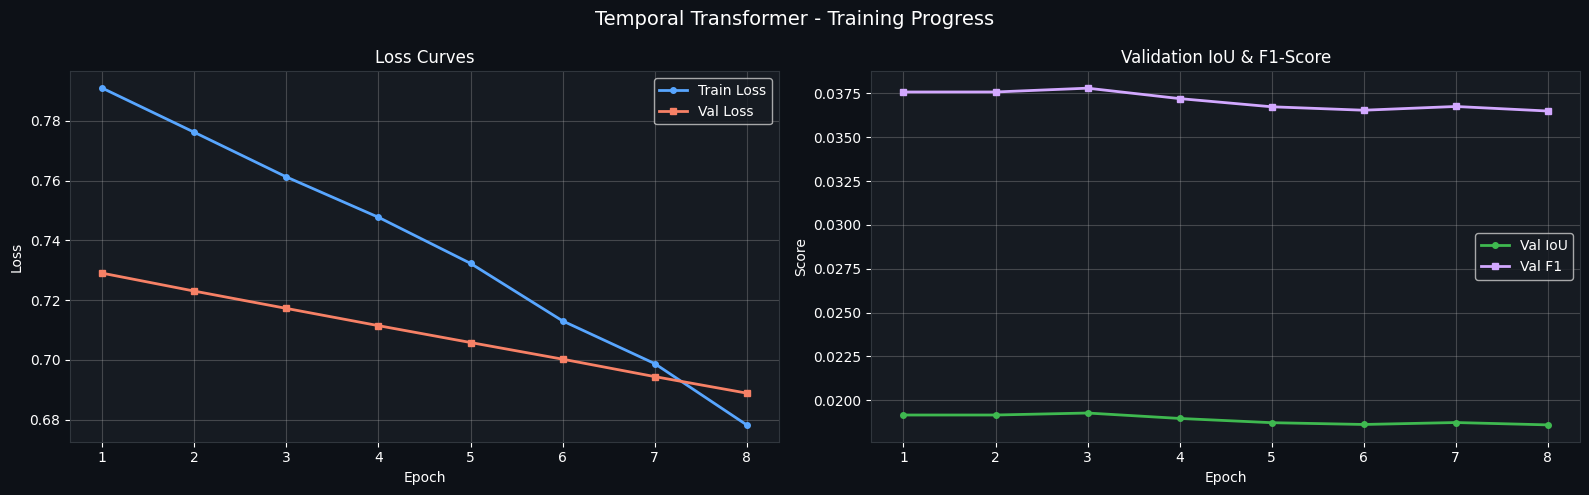

In [5]:
epochs_range = range(1, len(train_losses)+1)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
fig.suptitle('Temporal Transformer - Training Progress', fontsize=14, color='white')

axes[0].plot(epochs_range, train_losses, '#58a6ff', linewidth=2, label='Train Loss', marker='o', ms=4)
axes[0].plot(epochs_range, val_losses, '#f78166', linewidth=2, label='Val Loss', marker='s', ms=4)
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].set_title('Loss Curves')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

axes[1].plot(epochs_range, val_ious, '#3fb950', linewidth=2, label='Val IoU', marker='o', ms=4)
axes[1].plot(epochs_range, val_f1s,  '#d2a8ff', linewidth=2, label='Val F1',  marker='s', ms=4)
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Score')
axes[1].set_title('Validation IoU & F1-Score')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/transformer_training.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 6: Generate Water Segmentation Predictions

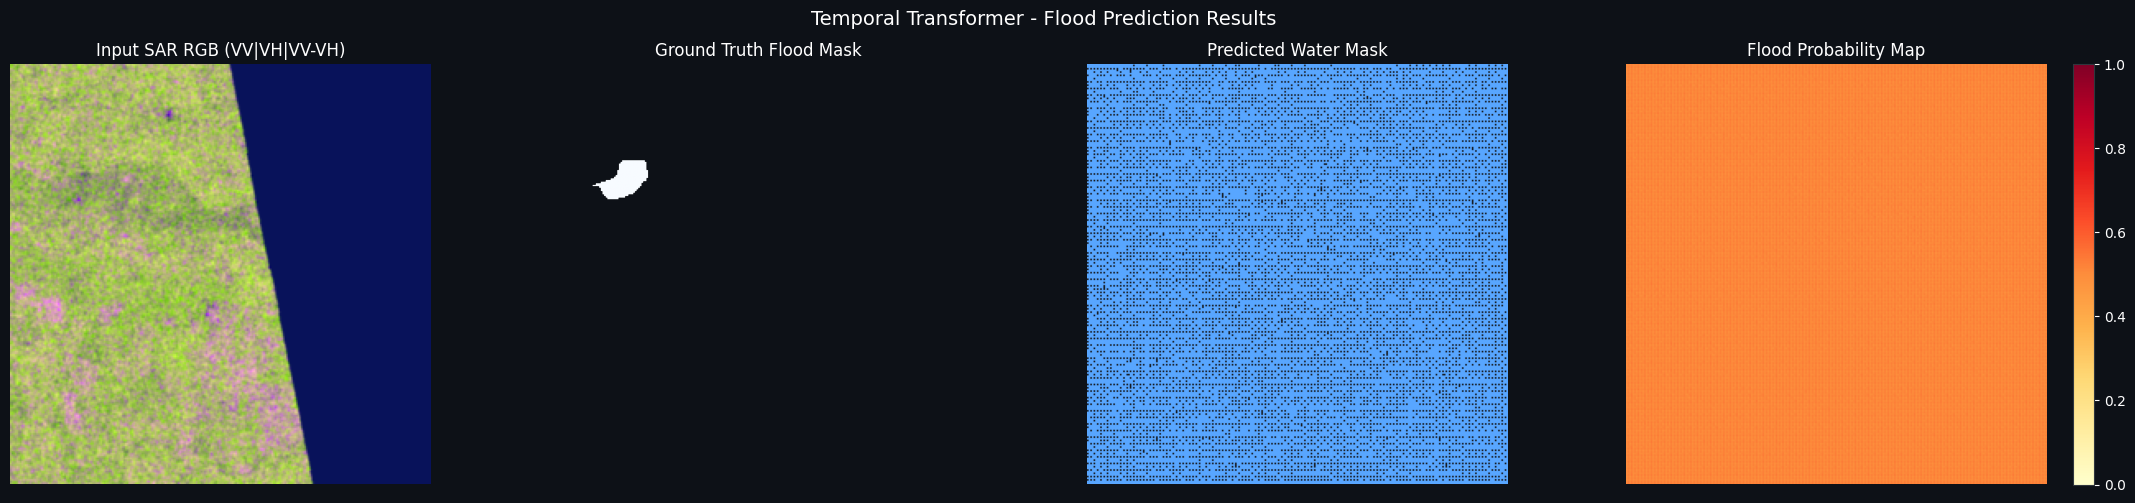

In [6]:
models_dir = os.path.join(ROOT_DIR, 'models')
model.load_state_dict(torch.load(os.path.join(models_dir, 'best_temporal_model.pth'), weights_only=True))
model.eval()

seq_data, target = next(iter(test_loader))
seq_data = seq_data.to(device)

with torch.no_grad():
    logits = model(seq_data)
    proba = torch.softmax(logits, dim=1)[:, 1, :, strip] if hasattr(logits, 'strip') else torch.softmax(logits, dim=1)[:, 1, :, :]
    predicted_mask = torch.argmax(logits, dim=1).squeeze(0).cpu().numpy()
    proba_map = proba.squeeze(0).cpu().numpy()

vv = seq_data[0, -1, 0].cpu().numpy()
vh = seq_data[0, -1, 1].cpu().numpy()

def norm(x):
    return (x - x.min()) / (x.max() - x.min() + 1e-8)
rgb = np.stack([norm(vv), norm(vh), norm(vv - vh)], axis=-1)

true_lbl = target.squeeze(0).numpy().astype(float)
true_lbl[true_lbl == -1] = np.nan

fig, axes = plt.subplots(1, 4, figsize=(22, 5))
fig.suptitle('Temporal Transformer - Flood Prediction Results', fontsize=14, color='white')

axes[0].imshow(rgb)
axes[0].set_title('Input SAR RGB (VV|VH|VV-VH)')
axes[0].axis('off')

axes[1].imshow(true_lbl, cmap='Blues', vmin=0, vmax=1)
axes[1].set_title('Ground Truth Flood Mask')
axes[1].axis('off')

axes[2].imshow(predicted_mask, cmap=ListedColormap(['#161b22', '#58a6ff']))
axes[2].set_title('Predicted Water Mask')
axes[2].axis('off')

im = axes[3].imshow(proba_map, cmap='YlOrRd', vmin=0, vmax=1)
axes[3].set_title('Flood Probability Map')
axes[3].axis('off')
plt.colorbar(im, ax=axes[3], fraction=0.046)

plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/transformer_predictions.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()


## Step 7: Spatio-Temporal Change Detection

Time Step 1 Flood Area: 5.667 km2
Time Step 2 Flood Area: 5.647 km2
Flood Spread Rate:      -0.020 km2


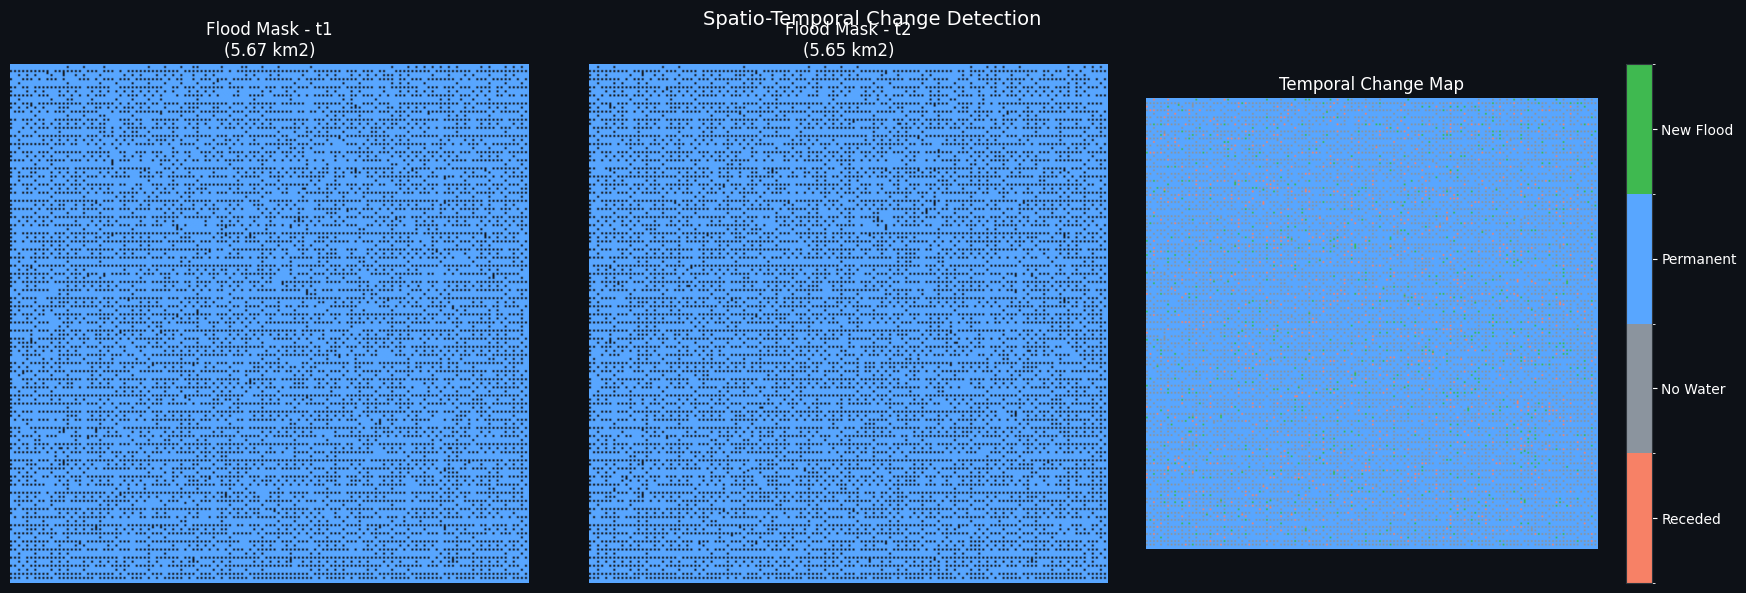

In [7]:
if len(test_seqs) >= 2:
    seq1, _ = test_dataset[0]
    seq2, _ = test_dataset[1]

    with torch.no_grad():
        out1 = model(seq1.unsqueeze(0).to(device))
        mask1 = torch.argmax(out1, dim=1).squeeze(0).cpu().numpy()
        out2 = model(seq2.unsqueeze(0).to(device))
        mask2 = torch.argmax(out2, dim=1).squeeze(0).cpu().numpy()

    change_map = np.zeros_like(mask2, dtype=int)
    change_map[(mask1 == 1) & (mask2 == 1)] = 1   # Permanent Water
    change_map[(mask1 == 0) & (mask2 == 1)] = 2   # New Flood
    change_map[(mask1 == 1) & (mask2 == 0)] = -1  # Receded Water

    pixel_area_sqm = 100
    area1 = np.sum(mask1) * pixel_area_sqm / 1e6
    area2 = np.sum(mask2) * pixel_area_sqm / 1e6

    print(f'Time Step 1 Flood Area: {area1:.3f} km2')
    print(f'Time Step 2 Flood Area: {area2:.3f} km2')
    print(f'Flood Spread Rate:      {area2 - area1:+.3f} km2')

    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.suptitle('Spatio-Temporal Change Detection', fontsize=14, color='white')

    axes[0].imshow(mask1, cmap=ListedColormap(['#161b22', '#58a6ff']))
    axes[0].set_title(f'Flood Mask - t1\n({area1:.2f} km2)')
    axes[0].axis('off')

    axes[1].imshow(mask2, cmap=ListedColormap(['#161b22', '#58a6ff']))
    axes[1].set_title(f'Flood Mask - t2\n({area2:.2f} km2)')
    axes[1].axis('off')

    cmap_change = ListedColormap(['#f78166', '#8b949e', '#58a6ff', '#3fb950'])
    bounds = [-1.5, -0.5, 0.5, 1.5, 2.5]
    norm = plt.cm.colors.BoundaryNorm(bounds, cmap_change.N)
    im = axes[2].imshow(change_map, cmap=cmap_change, norm=norm)
    cbar = plt.colorbar(im, ax=axes[2], ticks=[-1, 0, 1, 2])
    cbar.ax.set_yticklabels(['Receded', 'No Water', 'Permanent', 'New Flood'])
    axes[2].set_title('Temporal Change Map')
    axes[2].axis('off')

    plt.tight_layout()
    plt.savefig(os.path.join(ROOT_DIR, 'data/change_detection.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
    plt.show()


## Step 8: Final Performance Summary

=== Temporal Transformer - Test Set Performance ===
IoU (Jaccard):  0.0521
Accuracy:       0.1744
Precision:      0.0525
Recall:         0.8652
F1-Score:       0.0990


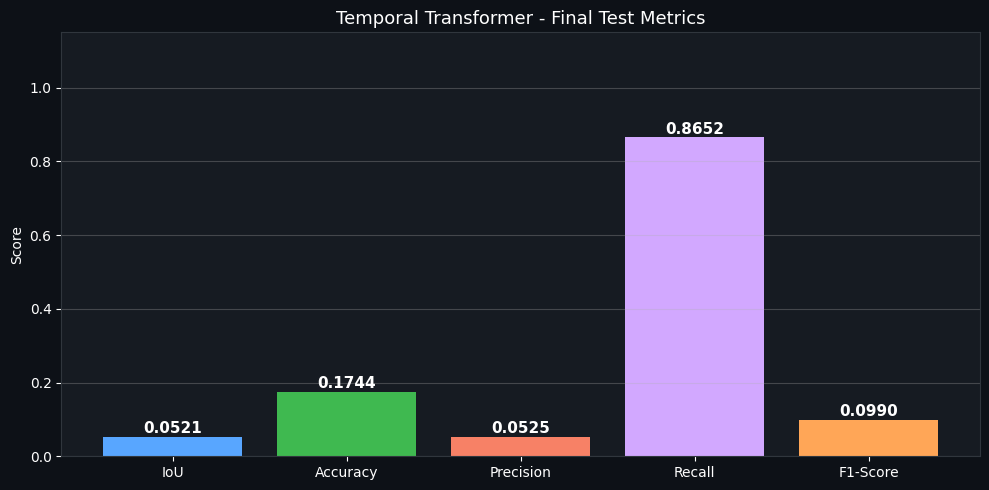

In [8]:
model.eval()
all_preds, all_targets = [], []

with torch.no_grad():
    for seq_data, target in test_loader:
        seq_data = seq_data.to(device)
        outputs = model(seq_data)
        preds = torch.argmax(outputs, dim=1)
        all_preds.append(preds.cpu())
        all_targets.append(target)

all_preds   = torch.cat(all_preds)
all_targets = torch.cat(all_targets)
iou, acc, prec, rec, f1 = calculate_metrics(all_preds, all_targets)

print('=== Temporal Transformer - Test Set Performance ===')
print(f'IoU (Jaccard):  {iou:.4f}')
print(f'Accuracy:       {acc:.4f}')
print(f'Precision:      {prec:.4f}')
print(f'Recall:         {rec:.4f}')
print(f'F1-Score:       {f1:.4f}')

metrics = {'IoU': iou, 'Accuracy': acc, 'Precision': prec, 'Recall': rec, 'F1-Score': f1}
fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(metrics.keys(), metrics.values(),
              color=['#58a6ff','#3fb950','#f78166','#d2a8ff','#ffa657'])
for bar, val in zip(bars, metrics.values()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
            f'{val:.4f}', ha='center', fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.set_title('Temporal Transformer - Final Test Metrics', fontsize=13)
ax.set_ylabel('Score')
ax.grid(True, axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(ROOT_DIR, 'data/transformer_metrics.png'), dpi=120, bbox_inches='tight', facecolor='#0d1117')
plt.show()
